=== HASIL EVALUASI MULTICLASS SVM (GLASS DATASET) ===
Akurasi Model : 72.09%

Classification Report:
              precision    recall  f1-score   support

           1       0.65      0.79      0.71        14
           2       0.71      0.67      0.69        15
           3       0.00      0.00      0.00         3
           5       1.00      1.00      1.00         3
           6       0.50      0.50      0.50         2
           7       0.86      1.00      0.92         6

    accuracy                           0.72        43
   macro avg       0.62      0.66      0.64        43
weighted avg       0.67      0.72      0.69        43



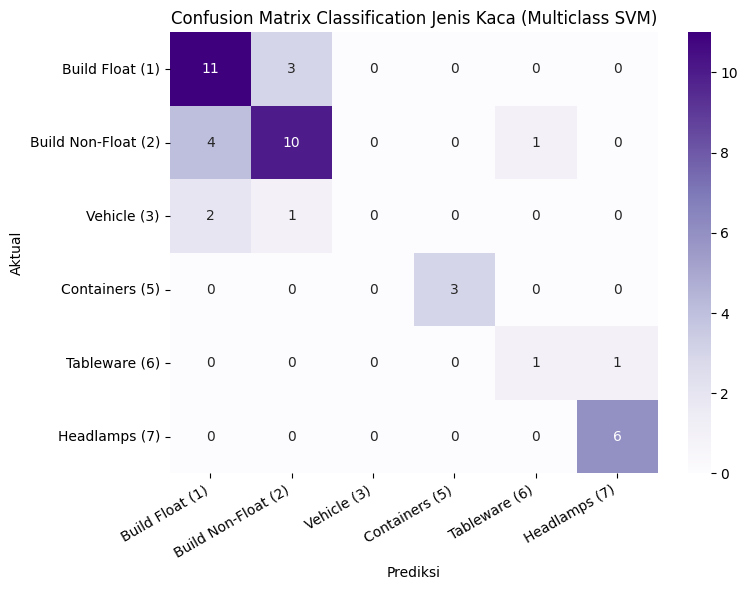

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. LOAD DATASET (UCI Glass Classification)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
column_names = ['ID', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']
df = pd.read_csv(url, header=None, names=column_names)

# Label Jenis Kaca (sesuai dokumentasi resmi UCI):
# 1: Building Windows (Float Processed)
# 2: Building Windows (Non-Float Processed)
# 3: Vehicle Windows
# 5: Containers
# 6: Tableware
# 7: Headlamps
glass_type_names = ['Build Float (1)', 'Build Non-Float (2)', 'Vehicle (3)', 'Containers (5)', 'Tableware (6)', 'Headlamps (7)']

# 2. PEMBERSIHAN DATA & PREPROCESSING
# A. Hapus kolom ID karena tidak prediktif
df = df.drop(columns=['ID'])

# B. Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['Type'])
y = df['Type']

# C. Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# D. Scaling Fitur (WAJIB untuk SVM!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. TRAINING MODEL MULTICLASS SVM
# decision_function_shape='ovr' (One-vs-Rest) untuk penanganan multiclass
model = SVC(kernel='rbf', C=2.0, gamma='scale', decision_function_shape='ovr', random_state=42)
model.fit(X_train_scaled, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print("=== HASIL EVALUASI MULTICLASS SVM (GLASS DATASET) ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 5. VISUALISASI CONFUSION MATRIX
fig, ax = plt.subplots(figsize=(8, 6))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    ax=ax,
    xticklabels=glass_type_names,
    yticklabels=glass_type_names
)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_title("Confusion Matrix Classification Jenis Kaca (Multiclass SVM)")

plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()